# Exploratory Data Analysis — I See You, ICU

IE 7275 Group A, MIMIC-IV. Combined from `01_eda.ipynb` (profiling, class imbalance, within-lab correlations) and `ICU_EDA_Project.ipynb` (cohort checks, IQR/Z-score, Figures 1–8).

Uses the **training split only**. `*_min24h` and `*_max24h` are already dropped in `features.py` (they matched `*_last`).

## 1. Load the data

Training snapshots from `features.parquet` plus `split.csv`. Figures go to `reports/figures/`.

In [1]:
%matplotlib inline
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from icu_forecast.config import ROOT, load_config
from icu_forecast.features import next_snapshot
from icu_forecast.prepare import load_features

cfg = load_config()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

df = load_features(cfg)
df = df[df.split == "train"].copy()
print("[1. Data Profiling]")
print("train snapshots:", f"{len(df):,}", "patients:", df.subject_id.nunique(), "admissions:", df.hadm_id.nunique())
df.head(10)


[1. Data Profiling]
train snapshots: 436,541 patients: 32398 admissions: 88769


,subject_id,hadm_id,snapshot_time,y_24h,y_48h,age,gender_male,admission_type,admission_location,careunit,...,magnesium_count24h,pco2_count24h,ph_count24h,platelets_count24h,po2_count24h,potassium_count24h,sodium_count24h,troponin_t_count24h,wbc_count24h,split
3,10000690,23280645,2150-09-17 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,train
4,10000690,23280645,2150-09-18 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,2.0,1.0,train
5,10000690,23280645,2150-09-19 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,1.0,0.0,0.0,2.0,0.0,1.0,1.0,1.0,2.0,train
6,10000690,23280645,2150-09-20 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,1.0,0.0,0.0,0.0,0.0,2.0,2.0,1.0,0.0,train
7,10000690,23280645,2150-09-21 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,train
8,10000690,23280645,2150-09-22 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,1.0,0.0,0.0,3.0,0.0,2.0,2.0,0.0,3.0,train
9,10000690,23280645,2150-09-23 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,train
10,10000690,23280645,2150-09-24 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,train
11,10000826,21086876,2146-12-19 08:00:00,0,0,32,0,DIRECT EMER.,CLINIC REFERRAL,Neurology,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,train
12,10000826,21086876,2146-12-20 08:00:00,0,0,32,0,DIRECT EMER.,CLINIC REFERRAL,Neurology,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,train


## 2. Check and clean the data

Look at data types, repeated records, and missing values. Do not fill missing lab values here.

In [2]:
print("\n[Data Shape]", df.shape)
print("\n[Data Types]")
print(df.dtypes)
print("\nExact duplicates:", df.duplicated().sum())
print("Repeated snapshot keys:", df.duplicated(["hadm_id", "snapshot_time"]).sum())
print("\n[Missing Values Count]")
print(df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False).head(20))
if df.duplicated(["hadm_id", "snapshot_time"]).any():
    raise ValueError("Repeated snapshot keys: check the source data before proceeding.")



[Data Shape] (436541, 102)

[Data Types]
subject_id                      int64
hadm_id                         int64
snapshot_time          datetime64[ns]
y_24h                            int8
y_48h                            int8
                            ...      
potassium_count24h            float32
sodium_count24h               float32
troponin_t_count24h           float32
wbc_count24h                  float32
split                          object
Length: 102, dtype: object



Exact duplicates: 0
Repeated snapshot keys: 0

[Missing Values Count]


pco2_delta          418405
po2_delta           418404
ph_delta            414289
troponin_t_delta    408609
lactate_delta       405495
pco2_last           387965
po2_last            387961
troponin_t_last     386684
ph_last             380440
albumin_delta       347860
lactate_last        342266
bilirubin_delta     296824
inr_delta           258462
albumin_last        249179
bilirubin_last      199074
calcium_delta       150842
omr_bmi             149836
inr_last            149315
magnesium_delta     144104
omr_weight_lbs      130860
dtype: int64


In [3]:
print("admission_type:\n", df["admission_type"].value_counts(), "\n")
print("admission_location:\n", df["admission_location"].value_counts(), "\n")
print("careunit:\n", df["careunit"].value_counts())


admission_type:
 admission_type
EW EMER.                  189718
OBSERVATION ADMIT         143481
DIRECT EMER.               48602
URGENT                     25540
EU OBSERVATION             19788
DIRECT OBSERVATION          7484
AMBULATORY OBSERVATION      1928
Name: count, dtype: int64 

admission_location:
 admission_location
EMERGENCY ROOM                            186984
PHYSICIAN REFERRAL                        106678
WALK-IN/SELF REFERRAL                      48610
TRANSFER FROM HOSPITAL                     42773
CLINIC REFERRAL                            29841
TRANSFER FROM SKILLED NURSING FACILITY     13060
PROCEDURE SITE                              4706
PACU                                        3388
AMBULATORY SURGERY TRANSFER                  375
INFORMATION NOT AVAILABLE                    109
INTERNAL TRANSFER TO OR FROM PSYCH            17
Name: count, dtype: int64 



careunit:
 careunit
Medicine                                134582
Hematology/Oncology                      51371
Transplant                               37737
Med/Surg                                 33987
Hematology/Oncology Intermediate         31480
Medicine/Cardiology                      28809
Vascular                                 21054
Neurology                                17869
Medicine/Cardiology Intermediate         12159
Med/Surg/GYN                             11580
Surgery/Trauma                           10293
Surgery                                  10032
Med/Surg/Trauma                          10022
Surgery/Pancreatic/Biliary/Bariatric      4867
Surgery/Vascular/Intermediate             4387
Cardiac Surgery                           3985
Medical/Surgical (Gynecology)             3141
Cardiology Surgery Intermediate           2680
Oncology                                  1582
Neuro Intermediate                        1485
Thoracic Surgery                        

## 3. Check patient selection and ICU targets

Adult patients with at least one prior admission in the last 365 days. A 24-hour transfer must also count as a 48-hour transfer.

In [4]:
needed = ["subject_id", "hadm_id", "snapshot_time", "age", "n_prior_adm_365d",
          "days_since_prev_disch", "hours_since_admit", "careunit", "y_24h", "y_48h"]
needed += [x + "_last" for x in ["creatinine", "glucose", "hemoglobin", "lactate", "sodium", "wbc"]]
missing_columns = [col for col in needed if col not in df.columns]
if missing_columns:
    raise ValueError("Missing columns: " + ", ".join(missing_columns))

print("Patients:", df["subject_id"].nunique())
print("Admissions:", df["hadm_id"].nunique())
assert df["y_24h"].isin([0, 1]).all() and df["y_48h"].isin([0, 1]).all()
assert (df["y_24h"] <= df["y_48h"]).all()
print("\n24-hour ICU labels:\n", df["y_24h"].value_counts())
print("\n48-hour ICU labels:\n", df["y_48h"].value_counts())

lab_names = ["creatinine_last", "glucose_last", "hemoglobin_last",
             "lactate_last", "sodium_last", "wbc_last"]


Patients: 32398
Admissions: 88769

24-hour ICU labels:
 y_24h
0    432641
1      3900
Name: count, dtype: int64

48-hour ICU labels:
 y_48h
0    429823
1      6718
Name: count, dtype: int64


## 4. Summary statistics and outliers

Use `describe()` and the IQR and Z-score methods. An unusual clinical result is not automatically an error.

[2. Statistical Summary]


             age  days_since_prev_disch  n_prior_adm_365d  hours_since_admit  \
count  436541.00              436541.00         436541.00          436541.00   
mean       63.86                  71.04              2.90             147.51   
std        16.36                  87.21              2.74             249.11   
min        18.00                   0.04              1.00               0.02   
25%        54.00                  10.12              1.00              34.55   
50%        65.00                  31.37              2.00              78.78   
75%        76.00                  98.89              4.00             160.32   
max       102.00                 364.99             56.00            5270.82   

       creatinine_last  glucose_last  hemoglobin_last  lactate_last  \
count        386712.00     385318.00        394244.00      94275.00   
mean              1.44        124.06            10.01          1.60   
std               1.63         54.52             1.96          0.7

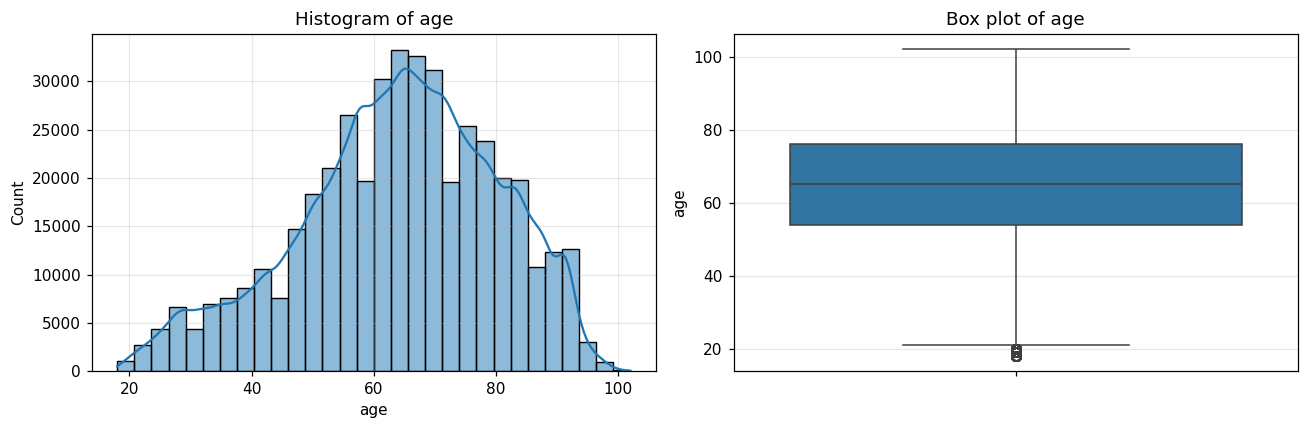

In [5]:
numeric_features = ["age", "days_since_prev_disch", "n_prior_adm_365d",
                    "hours_since_admit"] + lab_names
print("[2. Statistical Summary]")
print(df[numeric_features].describe().round(2))
print("\nMissing percentages:\n", (df[numeric_features].isna().mean() * 100).round(1))

print("\n[3. Outlier Detection]")
for name in ["age", "lactate_last"]:
    values = df[name].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_count = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
    z = (values - values.mean()) / values.std() if values.std() > 0 else values * 0
    print(name, "— IQR flags:", int(iqr_count), "; Z-score flags:", int((z.abs() > 3).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["age"], kde=True, ax=axes[0], bins=30)
axes[0].set_title("Histogram of age")
sns.boxplot(y=df["age"], ax=axes[1])
axes[1].set_title("Box plot of age")
fig.tight_layout()
plt.show()
fig.savefig(FIG / "eda_age_outliers.png")


## 5. Exploratory data analysis

### Figure 1 — Class imbalance

3,900 transfer in 436,541 records: 0.89%
6,718 transfer in 436,541 records: 1.54%


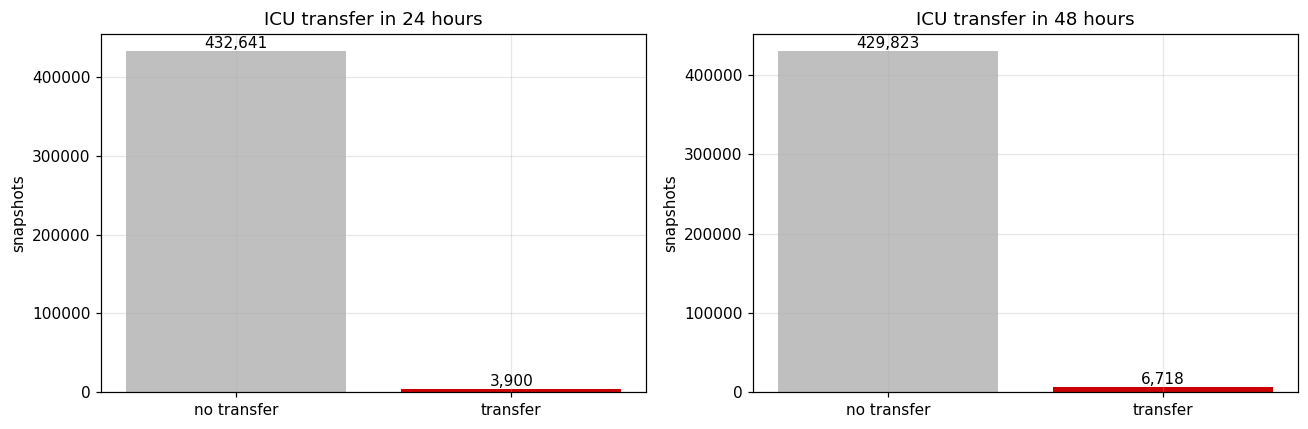

In [6]:
counts_1d = df["y_24h"].value_counts().sort_index()
counts_2d = df["y_48h"].value_counts().sort_index()
print(f"{counts_1d.get(1, 0):,} transfer in {len(df):,} records: {df['y_24h'].mean():.2%}")
print(f"{counts_2d.get(1, 0):,} transfer in {len(df):,} records: {df['y_48h'].mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in [
    (axes[0], counts_1d, "ICU transfer in 24 hours"),
    (axes[1], counts_2d, "ICU transfer in 48 hours"),
]:
    ax.bar(["no transfer", "transfer"], counts.reindex([0, 1], fill_value=0).values, color=["#BFBFBF", "#CC0000"])
    for i, v in enumerate(counts.reindex([0, 1], fill_value=0).values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
    ax.set_ylabel("snapshots")
    ax.set_title(title)
fig.tight_layout()
plt.show()
fig.savefig(FIG / "fig1_class_balance.png")


### Figure 2 — Patient and admission features

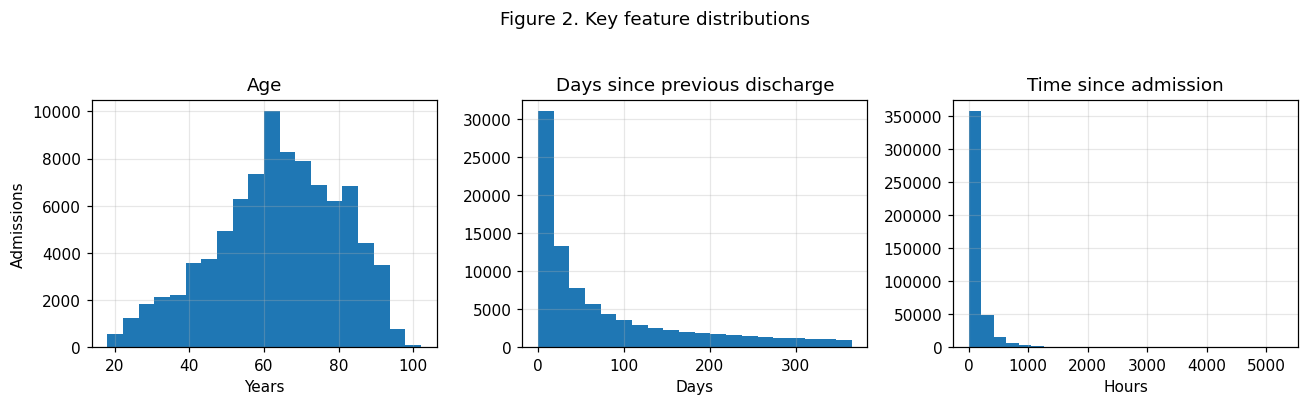

In [7]:
one = df.drop_duplicates("hadm_id")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(one["age"].dropna(), bins=20)
axes[0].set_title("Age")
axes[0].set_xlabel("Years")
axes[0].set_ylabel("Admissions")
axes[1].hist(one["days_since_prev_disch"].dropna(), bins=20)
axes[1].set_title("Days since previous discharge")
axes[1].set_xlabel("Days")
axes[2].hist(df["hours_since_admit"].dropna(), bins=25)
axes[2].set_title("Time since admission")
axes[2].set_xlabel("Hours")
fig.suptitle("Figure 2. Key feature distributions", y=1.04)
fig.tight_layout()
plt.show()
fig.savefig(FIG / "figure_02_patient_distributions.png")


### Figure 3 — Laboratory distributions

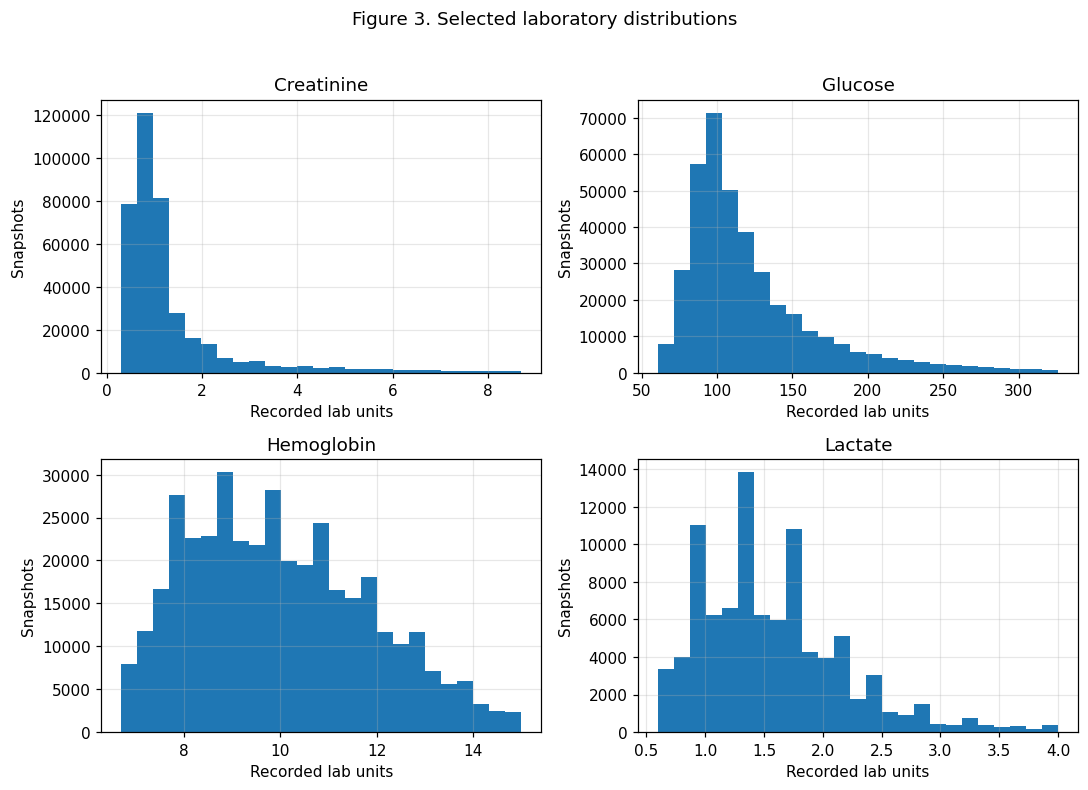

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, name in zip(axes.flat, ["creatinine_last", "glucose_last", "hemoglobin_last", "lactate_last"]):
    values = df[name].dropna()
    if not values.empty:
        low, high = values.quantile([0.01, 0.99])
        ax.hist(values[values.between(low, high)], bins=25)
    ax.set_title(name.replace("_last", "").title())
    ax.set_xlabel("Recorded lab units")
    ax.set_ylabel("Snapshots")
fig.suptitle("Figure 3. Selected laboratory distributions", y=1.02)
fig.tight_layout()
plt.show()
fig.savefig(FIG / "figure_03_labs.png")


### Figure 4 — Missing laboratory measurements

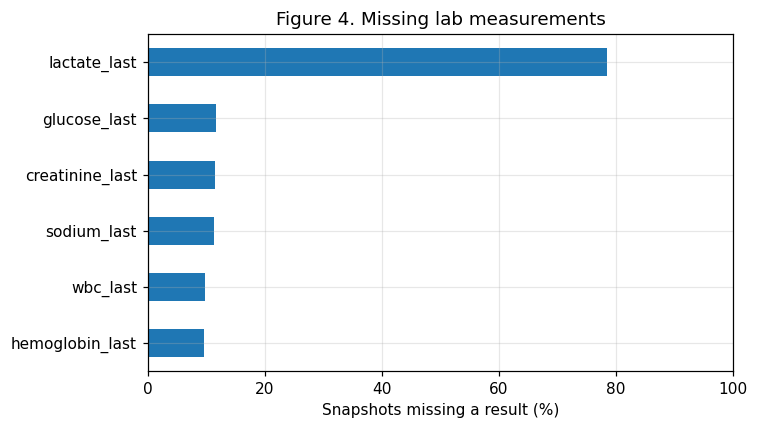

hemoglobin_last     9.7
wbc_last            9.8
sodium_last        11.4
creatinine_last    11.4
glucose_last       11.7
lactate_last       78.4
dtype: float64


In [9]:
missing_pct = (df[lab_names].isna().mean() * 100).sort_values()
ax = missing_pct.plot(kind="barh", figsize=(7, 4))
ax.set_title("Figure 4. Missing lab measurements")
ax.set_xlabel("Snapshots missing a result (%)")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()
plt.savefig(FIG / "figure_04_missing_labs.png")
print(missing_pct.round(1))


### Figure 5 — Features compared with ICU transfer

<Figure size 704x528 with 0 Axes>

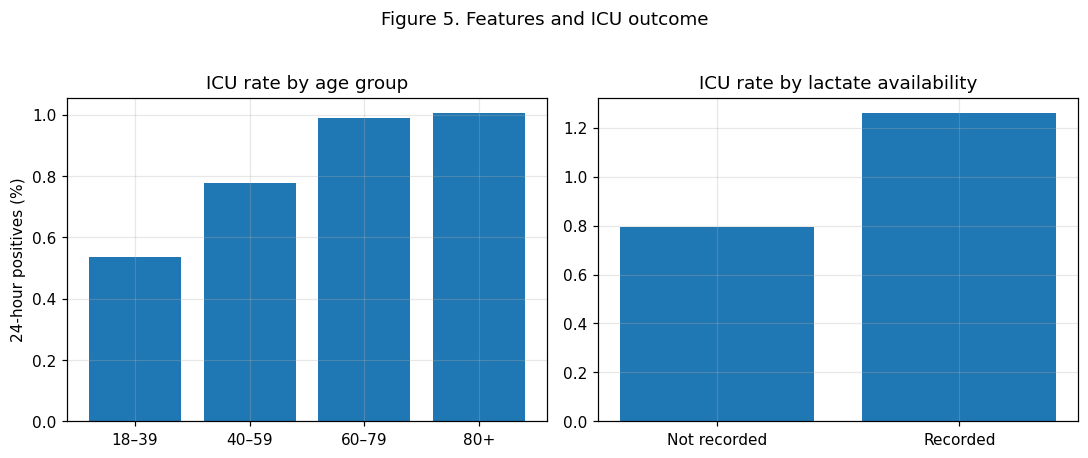

ICU rates by age group:
                mean    size
age_group                  
18–39      0.005369   39110
40–59      0.007774  121695
60–79      0.009910  196174
80+        0.010055   79562
ICU rates by lactate availability:
                  mean    size
has_lactate                  
False        0.007924  342266
True         0.012601   94275


In [10]:
df["age_group"] = pd.cut(df["age"], bins=[18, 40, 60, 80, np.inf],
                         right=False, labels=["18–39", "40–59", "60–79", "80+"])
df["has_lactate"] = df["lactate_last"].notna()
age_table = df.groupby("age_group", observed=True)["y_24h"].agg(["mean", "size"])
lactate_table = df.groupby("has_lactate")["y_24h"].agg(["mean", "size"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(age_table.index.astype(str), age_table["mean"] * 100)
axes[0].set_title("ICU rate by age group")
axes[0].set_ylabel("24-hour positives (%)")
order = lactate_table.reindex([False, True])
axes[1].bar(["Not recorded", "Recorded"], order["mean"] * 100)
axes[1].set_title("ICU rate by lactate availability")
fig.suptitle("Figure 5. Features and ICU outcome", y=1.03)
fig.tight_layout()
plt.show()
fig.savefig(FIG / "figure_05_feature_target.png")
print("ICU rates by age group:\n", age_table)
print("ICU rates by lactate availability:\n", lactate_table)


### Labs versus the 24-hour target (rate by decile)

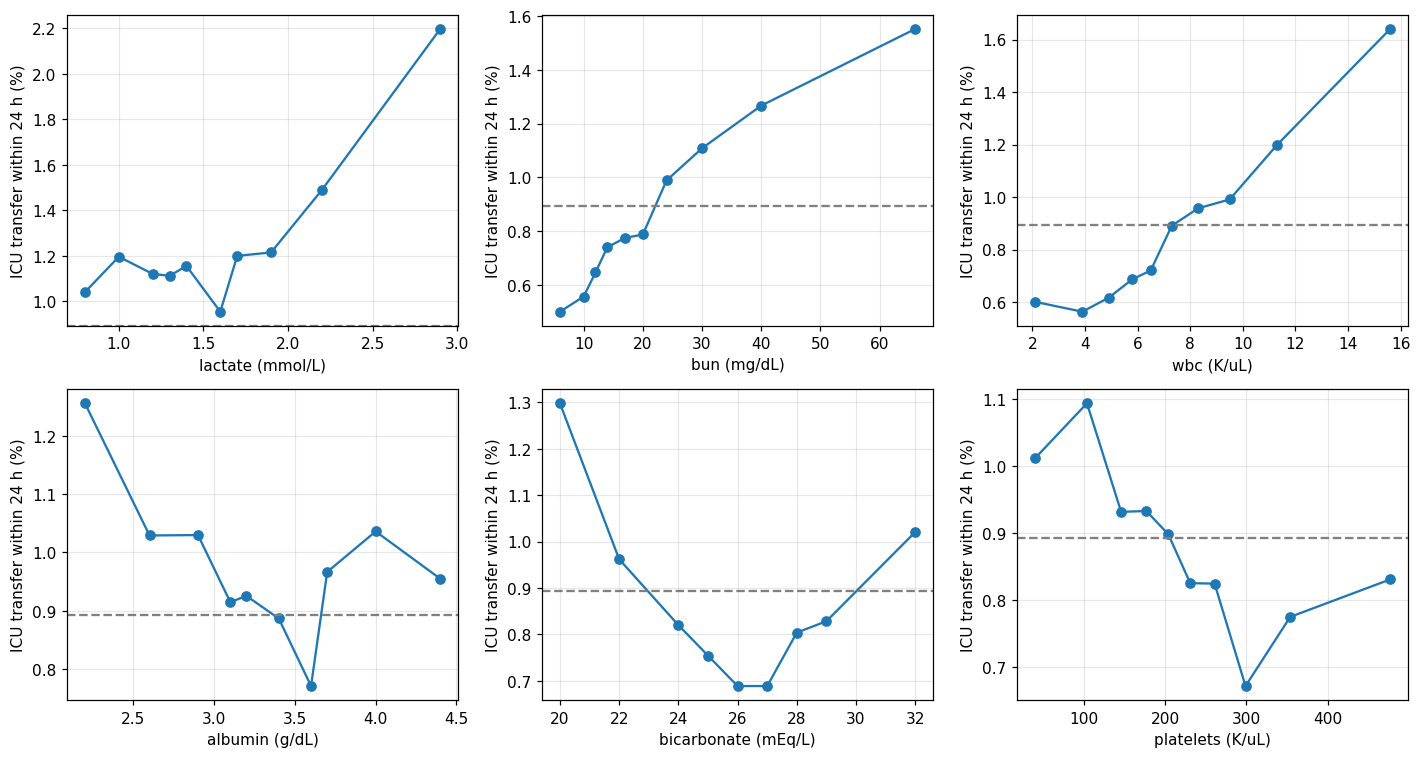

In [11]:
base = df.y_24h.mean()
units = {"lactate_last": "mmol/L", "bun_last": "mg/dL", "wbc_last": "K/uL",
         "albumin_last": "g/dL", "bicarbonate_last": "mEq/L", "platelets_last": "K/uL"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, unit) in zip(axes.flat, units.items()):
    s = df[[col, "y_24h"]].dropna()
    s["bin"] = pd.qcut(s[col], 10, duplicates="drop")
    r = s.groupby("bin", observed=True).agg(x=(col, "median"), rate=("y_24h", "mean"))
    ax.plot(r.x, r.rate * 100, marker="o")
    ax.axhline(base * 100, ls="--", color="grey")
    ax.set_xlabel(f"{col.replace('_last', '')} ({unit})")
    ax.set_ylabel("ICU transfer within 24 h (%)")
fig.tight_layout()
plt.show()
fig.savefig(FIG / "fig3_labs_vs_target.png")


### Informative missingness: was the lab ordered in the last 24 h?

            share_measured  rate_if_measured  rate_if_not
lab                                                      
lactate             0.0394            0.0361       0.0078
ph                  0.0244            0.0471       0.0080
troponin_t          0.0313            0.0228       0.0085
inr                 0.3386            0.0133       0.0067
albumin             0.1565            0.0124       0.0083
magnesium           0.6562            0.0098       0.0074
creatinine          0.7136            0.0097       0.0071


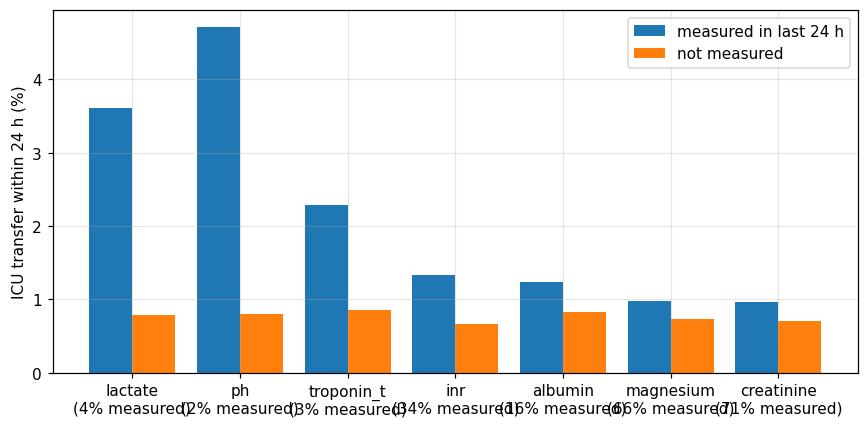

In [12]:
labs = ["lactate", "ph", "troponin_t", "inr", "albumin", "magnesium", "creatinine"]
rows = []
for lab in labs:
    measured = df[f"{lab}_count24h"] > 0
    rows.append({"lab": lab, "share_measured": measured.mean(),
                 "rate_if_measured": df.y_24h[measured].mean(),
                 "rate_if_not": df.y_24h[~measured].mean()})
miss = pd.DataFrame(rows).set_index("lab")
print(miss.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(miss))
ax.bar(x - 0.2, miss.rate_if_measured * 100, 0.4, label="measured in last 24 h")
ax.bar(x + 0.2, miss.rate_if_not * 100, 0.4, label="not measured")
ax.set_xticks(x, [f"{l}\n({s:.0%} measured)" for l, s in zip(miss.index, miss.share_measured)])
ax.set_ylabel("ICU transfer within 24 h (%)")
ax.legend()
fig.tight_layout()
plt.show()
fig.savefig(FIG / "fig4_missingness_vs_target.png")


### Figure 6 — Correlations between features

Pairwise Pearson correlation of age, stay timing, and selected last lab values.

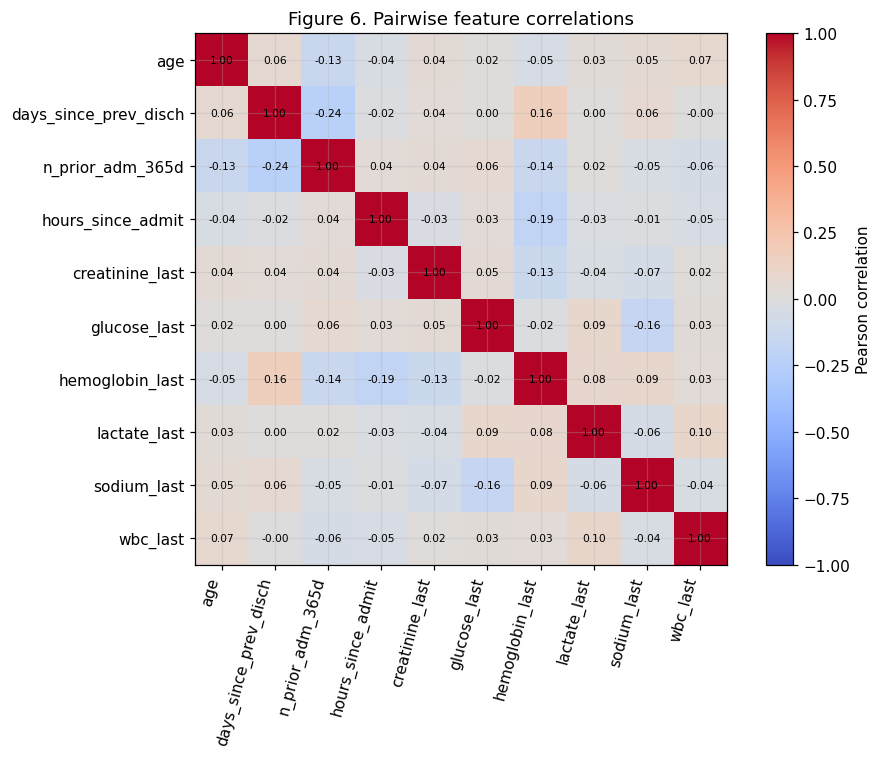

In [13]:
correlation = df[numeric_features].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_features)), numeric_features, rotation=75, ha="right")
ax.set_yticks(range(len(numeric_features)), numeric_features)
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        value = correlation.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Figure 6. Pairwise feature correlations")
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()
fig.savefig(FIG / "figure_06_correlations.png")


### Within-lab correlations (last, delta, count24h)

`min24h` / `max24h` were removed after this check showed they matched `last` (Spearman typically > 0.93).


--- Feature Group: albumin ---
                  albumin_last  albumin_delta  albumin_count24h
albumin_last             1.000          0.214            -0.019
albumin_delta            0.214          1.000             0.032
albumin_count24h        -0.019          0.032             1.000


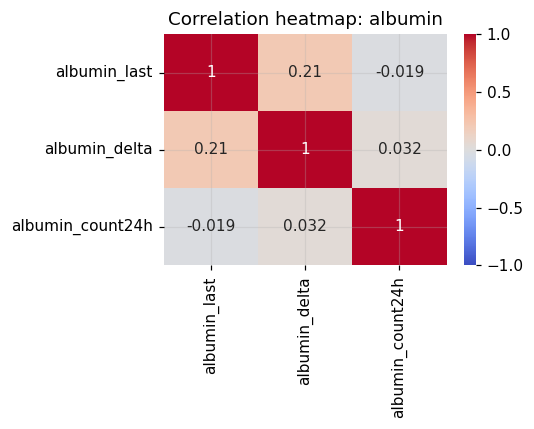


--- Feature Group: anion_gap ---
                    anion_gap_last  anion_gap_delta  anion_gap_count24h
anion_gap_last               1.000            0.371               0.028
anion_gap_delta              0.371            1.000              -0.039
anion_gap_count24h           0.028           -0.039               1.000


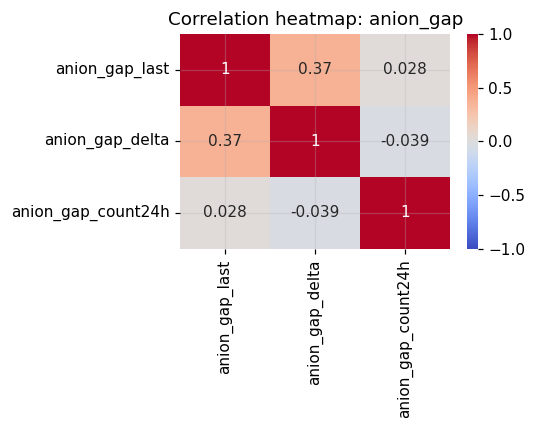


--- Feature Group: bicarbonate ---
                      bicarbonate_last  bicarbonate_delta  \
bicarbonate_last                 1.000              0.270   
bicarbonate_delta                0.270              1.000   
bicarbonate_count24h             0.012              0.014   

                      bicarbonate_count24h  
bicarbonate_last                     0.012  
bicarbonate_delta                    0.014  
bicarbonate_count24h                 1.000  


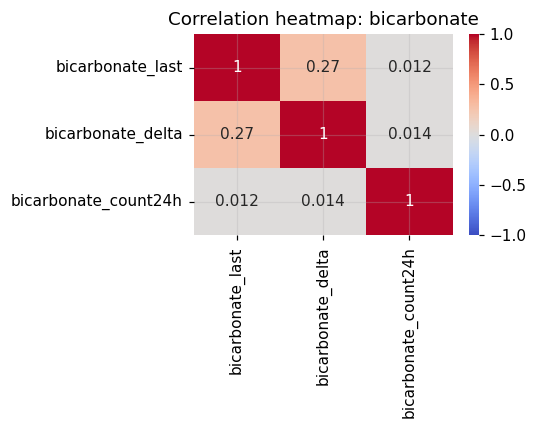


--- Feature Group: bilirubin ---
                    bilirubin_last  bilirubin_delta  bilirubin_count24h
bilirubin_last               1.000            0.113               0.160
bilirubin_delta              0.113            1.000              -0.006
bilirubin_count24h           0.160           -0.006               1.000


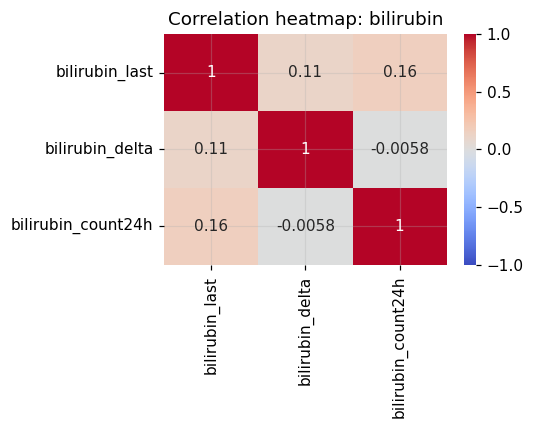


--- Feature Group: bun ---
              bun_last  bun_delta  bun_count24h
bun_last         1.000      0.094         0.149
bun_delta        0.094      1.000         0.002
bun_count24h     0.149      0.002         1.000


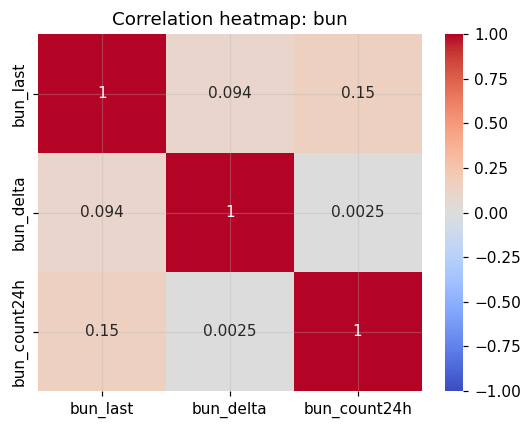


--- Feature Group: calcium ---
                  calcium_last  calcium_delta  calcium_count24h
calcium_last             1.000          0.242            -0.036
calcium_delta            0.242          1.000            -0.039
calcium_count24h        -0.036         -0.039             1.000


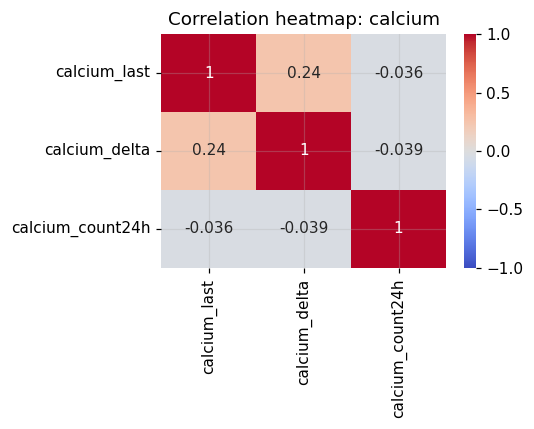


--- Feature Group: chloride ---
                   chloride_last  chloride_delta  chloride_count24h
chloride_last              1.000           0.220             -0.088
chloride_delta             0.220           1.000              0.017
chloride_count24h         -0.088           0.017              1.000


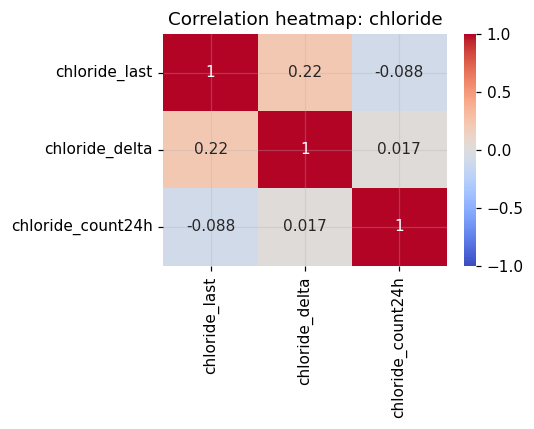


--- Feature Group: creatinine ---
                     creatinine_last  creatinine_delta  creatinine_count24h
creatinine_last                1.000             0.047                0.076
creatinine_delta               0.047             1.000               -0.009
creatinine_count24h            0.076            -0.009                1.000


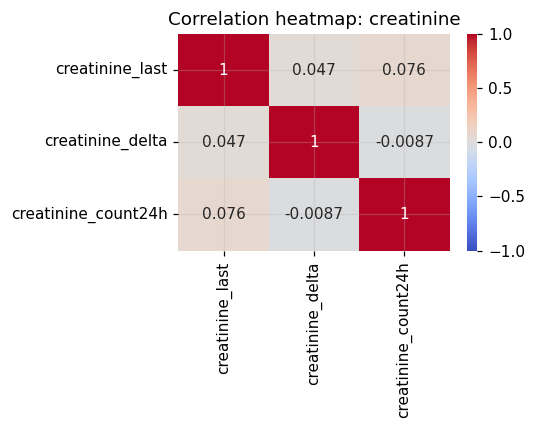


--- Feature Group: glucose ---
                  glucose_last  glucose_delta  glucose_count24h
glucose_last             1.000          0.435             0.068
glucose_delta            0.435          1.000            -0.013
glucose_count24h         0.068         -0.013             1.000


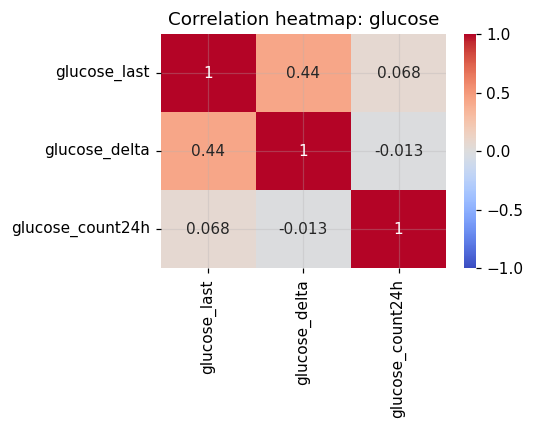


--- Feature Group: hemoglobin ---
                     hemoglobin_last  hemoglobin_delta  hemoglobin_count24h
hemoglobin_last                1.000             0.134               -0.150
hemoglobin_delta               0.134             1.000               -0.046
hemoglobin_count24h           -0.150            -0.046                1.000


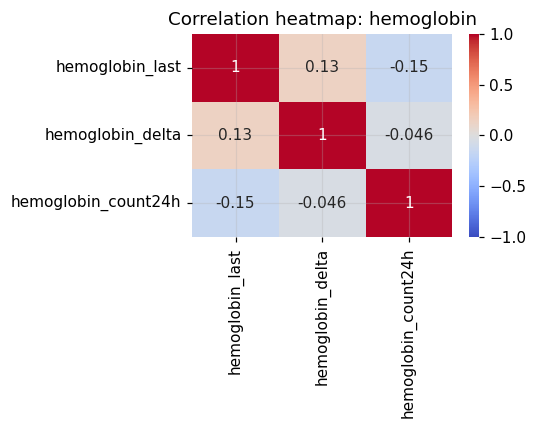


--- Feature Group: inr ---
              inr_last  inr_delta  inr_count24h
inr_last         1.000      0.128         0.238
inr_delta        0.128      1.000        -0.009
inr_count24h     0.238     -0.009         1.000


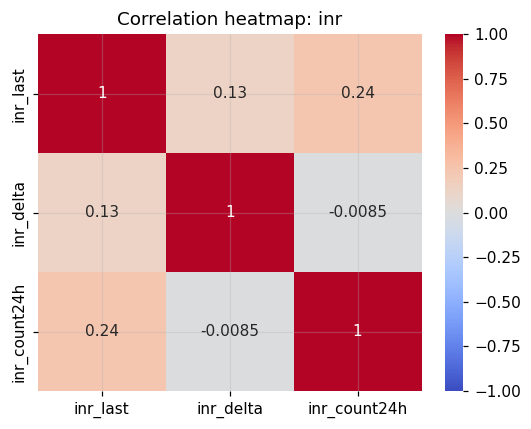


--- Feature Group: lactate ---
                  lactate_last  lactate_delta  lactate_count24h
lactate_last             1.000          0.143             0.111
lactate_delta            0.143          1.000            -0.008
lactate_count24h         0.111         -0.008             1.000


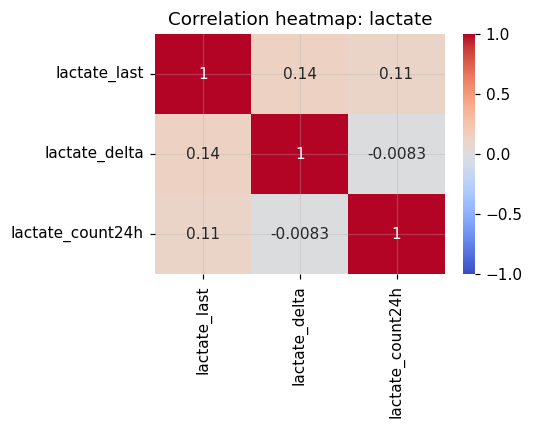


--- Feature Group: magnesium ---
                    magnesium_last  magnesium_delta  magnesium_count24h
magnesium_last               1.000            0.396               0.075
magnesium_delta              0.396            1.000               0.004
magnesium_count24h           0.075            0.004               1.000


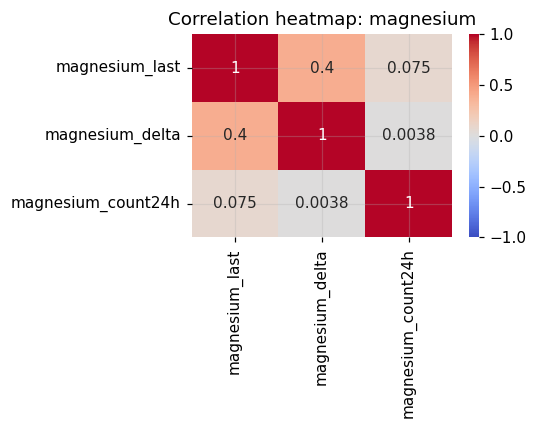


--- Feature Group: pco2 ---
               pco2_last  pco2_delta  pco2_count24h
pco2_last          1.000       0.246          0.031
pco2_delta         0.246       1.000         -0.023
pco2_count24h      0.031      -0.023          1.000


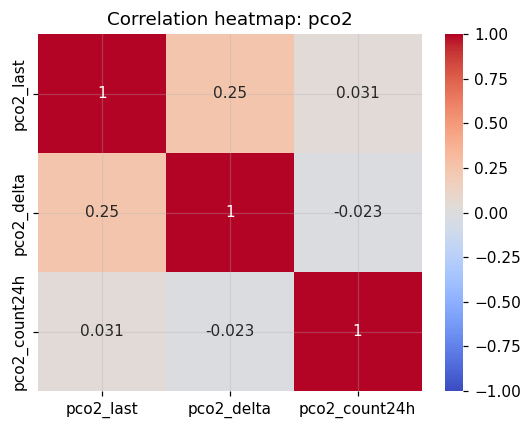


--- Feature Group: ph ---
             ph_last  ph_delta  ph_count24h
ph_last        1.000     0.322       -0.026
ph_delta       0.322     1.000        0.005
ph_count24h   -0.026     0.005        1.000


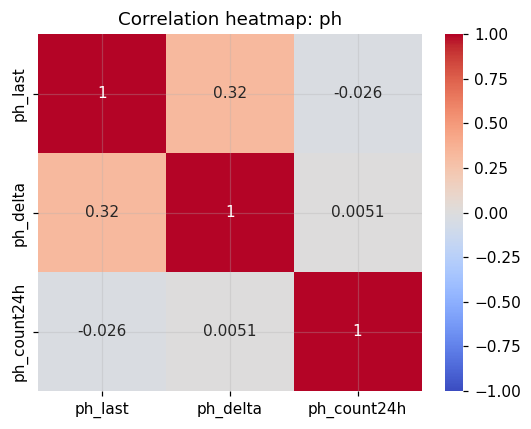


--- Feature Group: platelets ---
                    platelets_last  platelets_delta  platelets_count24h
platelets_last               1.000            0.117              -0.106
platelets_delta              0.117            1.000              -0.031
platelets_count24h          -0.106           -0.031               1.000


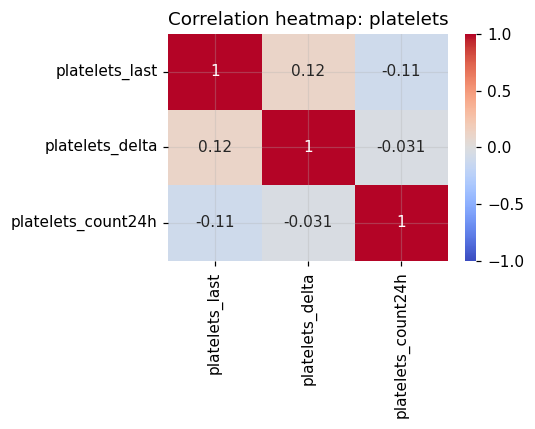


--- Feature Group: po2 ---
              po2_last  po2_delta  po2_count24h
po2_last         1.000      0.456         0.021
po2_delta        0.456      1.000         0.018
po2_count24h     0.021      0.018         1.000


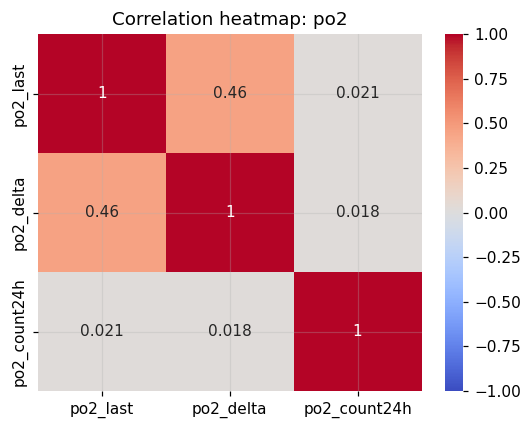


--- Feature Group: potassium ---
                    potassium_last  potassium_delta  potassium_count24h
potassium_last               1.000            0.354               0.005
potassium_delta              0.354            1.000              -0.018
potassium_count24h           0.005           -0.018               1.000


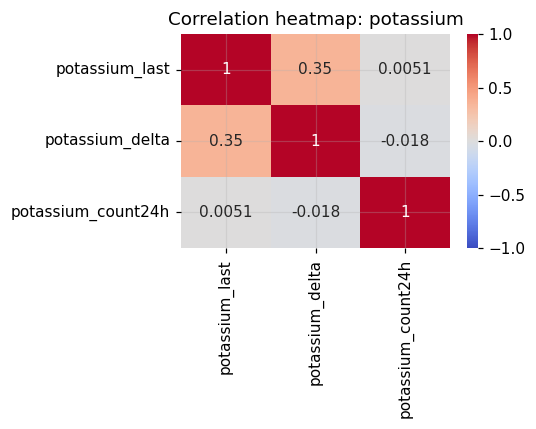


--- Feature Group: sodium ---
                 sodium_last  sodium_delta  sodium_count24h
sodium_last            1.000         0.278           -0.066
sodium_delta           0.278         1.000           -0.007
sodium_count24h       -0.066        -0.007            1.000


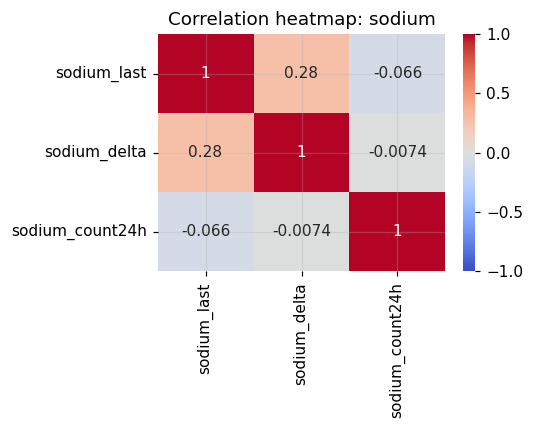


--- Feature Group: troponin_t ---
                     troponin_t_last  troponin_t_delta  troponin_t_count24h
troponin_t_last                1.000             0.033                0.102
troponin_t_delta               0.033             1.000                0.045
troponin_t_count24h            0.102             0.045                1.000


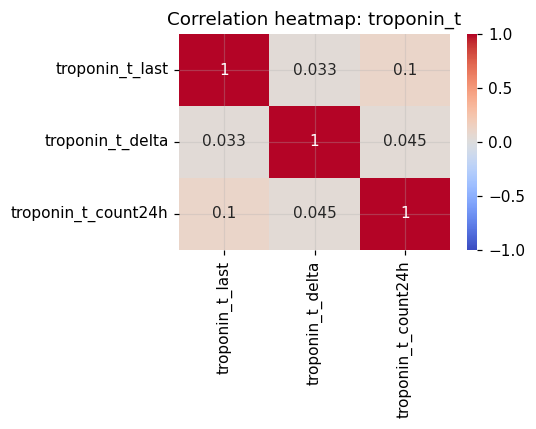


--- Feature Group: wbc ---
              wbc_last  wbc_delta  wbc_count24h
wbc_last         1.000      0.097         0.012
wbc_delta        0.097      1.000        -0.005
wbc_count24h     0.012     -0.005         1.000


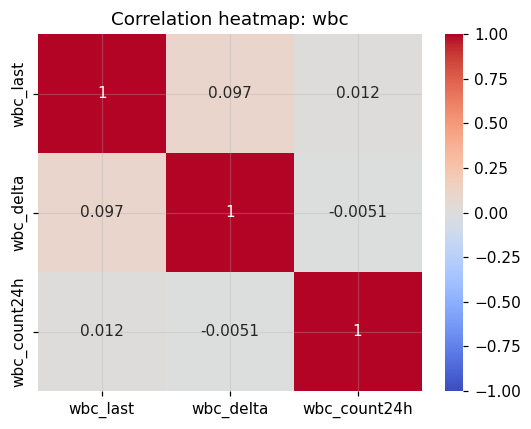

In [14]:
lab_prefixes = sorted({c.replace("_last", "") for c in df.columns if c.endswith("_last")})
for prefix in lab_prefixes:
    cols = [c for c in (f"{prefix}_last", f"{prefix}_delta", f"{prefix}_count24h") if c in df.columns]
    if len(cols) < 2:
        continue
    corr_matrix = df[cols].corr(method="pearson")
    print(f"\n--- Feature Group: {prefix} ---")
    print(corr_matrix.round(3))
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Correlation heatmap: {prefix}")
    fig.tight_layout()
    plt.show()


### Spearman correlation among last lab values

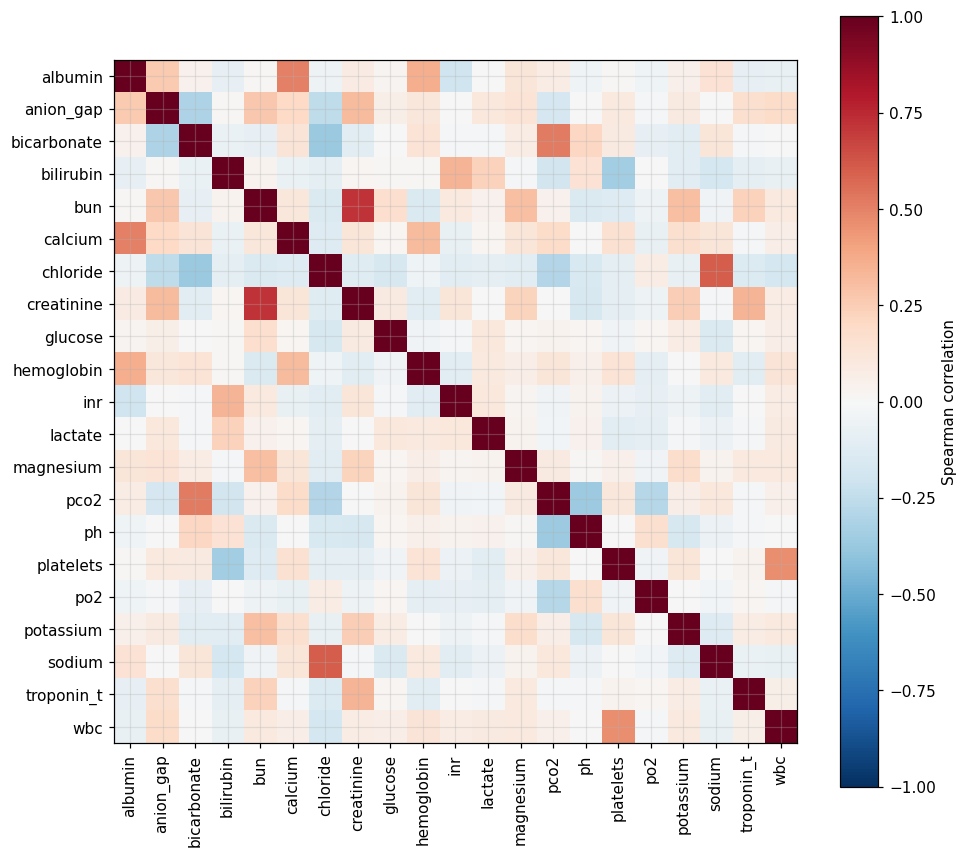

strongest pairs:
 bun_last          creatinine_last    0.72
chloride_last     sodium_last        0.61
bicarbonate_last  pco2_last          0.52
albumin_last      calcium_last       0.50
platelets_last    wbc_last           0.46
bicarbonate_last  chloride_last     -0.37
albumin_last      hemoglobin_last    0.37
pco2_last         ph_last           -0.36
dtype: float64


In [15]:
last_cols = [c for c in df.columns if c.endswith("_last")]
corr = df[last_cols].sample(min(200_000, len(df)), random_state=cfg["seed"]).corr(method="spearman")
names = [c.replace("_last", "") for c in last_cols]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=90)
ax.set_yticks(range(len(names)), names)
fig.colorbar(im, ax=ax, label="Spearman correlation")
fig.tight_layout()
plt.show()
fig.savefig(FIG / "fig5_lab_correlation.png")
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("strongest pairs:\n", pairs.head(8).round(2))


### Figure 7 — ICU risk over the hospital stay

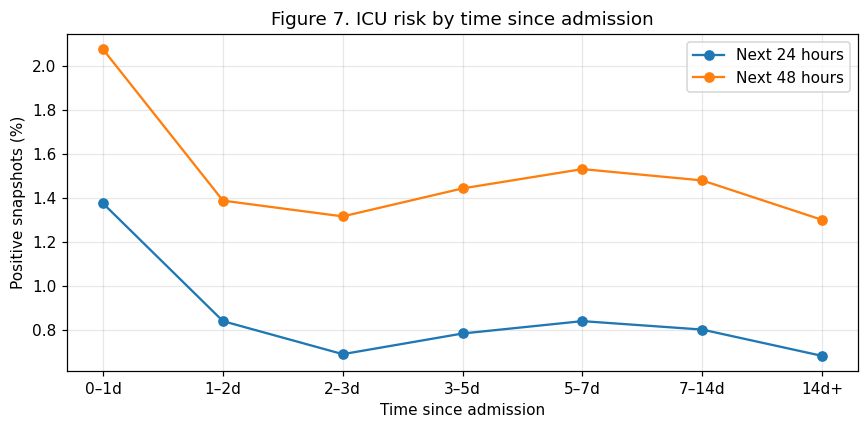

             y_24h  y_48h
stay_period              
0–1d          1.38   2.08
1–2d          0.84   1.39
2–3d          0.69   1.32
3–5d          0.79   1.44
5–7d          0.84   1.53
7–14d         0.80   1.48
14d+          0.68   1.30


In [16]:
df["stay_period"] = pd.cut(
    df["hours_since_admit"],
    bins=[0, 24, 48, 72, 120, 168, 336, np.inf], right=False,
    labels=["0–1d", "1–2d", "2–3d", "3–5d", "5–7d", "7–14d", "14d+"],
)
period_table = df.groupby("stay_period", observed=True)[["y_24h", "y_48h"]].mean() * 100
ax = period_table.plot(marker="o", figsize=(8, 4))
ax.set_title("Figure 7. ICU risk by time since admission")
ax.set_xlabel("Time since admission")
ax.set_ylabel("Positive snapshots (%)")
ax.legend(["Next 24 hours", "Next 48 hours"])
plt.tight_layout()
plt.show()
plt.savefig(FIG / "figure_07_time.png")
print(period_table.round(2))


### Figure 8 — Ward and patient-level structure

<Figure size 704x528 with 0 Axes>

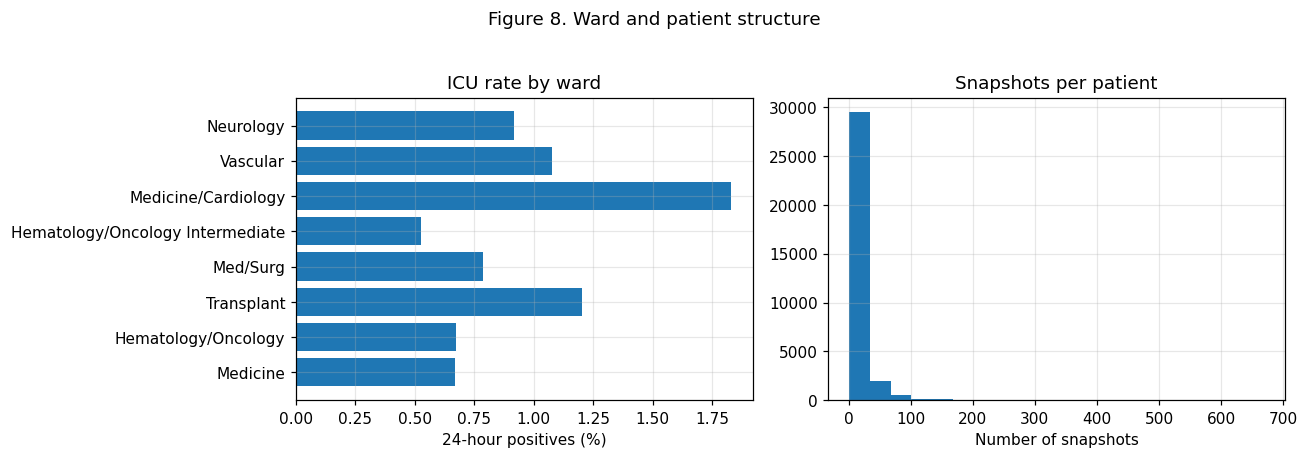

                                    mean    size
careunit                                        
Medicine                          0.0067  134582
Hematology/Oncology               0.0067   51371
Transplant                        0.0120   37737
Med/Surg                          0.0079   33987
Hematology/Oncology Intermediate  0.0053   31480
Medicine/Cardiology               0.0183   28809
Vascular                          0.0108   21054
Neurology                         0.0092   17869
count    32398.0
mean        13.5
std         23.4
min          1.0
25%          3.0
50%          6.0
75%         15.0
max        669.0
dtype: float64


In [17]:
ward_table = df.groupby("careunit")["y_24h"].agg(["mean", "size"])
ward_table = ward_table[ward_table["size"] >= 30].sort_values("size", ascending=False).head(8)
snapshots_per_patient = df.groupby("subject_id").size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(ward_table.index.astype(str), ward_table["mean"] * 100)
axes[0].set_title("ICU rate by ward")
axes[0].set_xlabel("24-hour positives (%)")
axes[1].hist(snapshots_per_patient, bins=20)
axes[1].set_title("Snapshots per patient")
axes[1].set_xlabel("Number of snapshots")
fig.suptitle("Figure 8. Ward and patient structure", y=1.03)
fig.tight_layout()
plt.show()
fig.savefig(FIG / "figure_08_grouping.png")
print(ward_table.round(4))
print(snapshots_per_patient.describe().round(1))


### Timing of ICU transfers relative to admission

Daily 08:00 snapshots cannot see transfers that happen before the first snapshot.

train ward-to-ICU admissions: 6,060
transferred before the first snapshot: 31.3%
count    6060.0
mean       87.0
std       169.1
min         0.0
25%         6.0
50%        29.8
75%       104.8
90%       223.1
max      4249.5
Name: hours_to_icu, dtype: float64


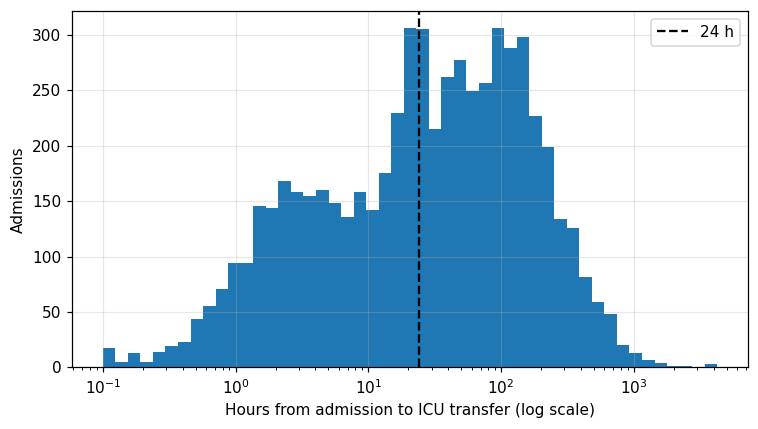

In [18]:
cohort = pd.read_parquet(cfg["paths"]["processed"] / "cohort.parquet")
split = pd.read_csv(cfg["paths"]["processed"] / "split.csv")
icu = cohort.merge(split, on="subject_id").query("split == 'train' and has_icu").copy()
icu["hours_to_icu"] = (icu.first_icu_time - icu.admittime).dt.total_seconds() / 3600
first_snap = next_snapshot(icu.admittime, cfg["snapshot"]["hour"])
icu["before_first_snapshot"] = icu.first_icu_time <= first_snap
print(f"train ward-to-ICU admissions: {len(icu):,}")
print(f"transferred before the first snapshot: {icu.before_first_snapshot.mean():.1%}")
print(icu.hours_to_icu.describe(percentiles=[.25, .5, .75, .9]).round(1))
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.logspace(-1, np.log10(max(icu.hours_to_icu.max(), 1) + 1), 50)
ax.hist(icu.hours_to_icu.clip(lower=0.1), bins=bins)
ax.set_xscale("log")
ax.axvline(24, color="k", ls="--", label="24 h")
ax.set_xlabel("Hours from admission to ICU transfer (log scale)")
ax.set_ylabel("Admissions")
ax.legend()
fig.tight_layout()
plt.show()
fig.savefig(FIG / "fig2_time_to_icu.png")


## 6. Dimension reduction (from the within-lab heatmaps)

- Removed `*_min24h` / `*_max24h` in `features.py` because they matched `*_last`.
- Kept `*_last`, `*_delta`, and `*_count24h` for each of the 21 labs.
- PCA of the routine lab panel is in `notebooks/02_pca.ipynb`.